# 01 – Explore the production data

> **Simulated data.** Generated by `forecasting/simulate.py` (production-line "digital twin"), because no public
> real hourly production-output data exists.

One production line, hourly, 2 years. Target for forecasting: `units_produced`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../../data/production_hourly.csv", parse_dates=["timestamp"])
df.head()

,timestamp,shift,product,status,units_produced,scrap_units,good_units
0,2024-10-01 00:00:00,night,A,running,105,2,103
1,2024-10-01 01:00:00,night,A,running,109,3,106
2,2024-10-01 02:00:00,night,A,running,101,3,98
3,2024-10-01 03:00:00,night,A,running,114,2,112
4,2024-10-01 04:00:00,night,A,running,112,4,108


In [2]:
df.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
timestamp,17520,NaN,NaN,NaN,2025-09-30 23:30:00,2024-10-01 00:00:00,2025-04-01 11:45:00,2025-09-30 23:30:00,2026-04-01 11:15:00,2026-09-30 23:00:00,NaN
shift,17520,4,early,4896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,17520,3,C,6232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status,17520,5,running,11970,NaN,NaN,NaN,NaN,NaN,NaN,NaN
units_produced,17520.0,NaN,NaN,NaN,77.571347,0.0,0.0,107.0,117.0,140.0,52.551494
scrap_units,17520.0,NaN,NaN,NaN,2.37637,0.0,0.0,2.0,4.0,15.0,2.286119
good_units,17520.0,NaN,NaN,NaN,75.194977,0.0,0.0,104.0,113.0,136.0,50.991608


## One week of output
Three shifts Mon–Fri, Saturday early shift only, Sunday off. Dips = shift handovers, changeovers, breakdowns.

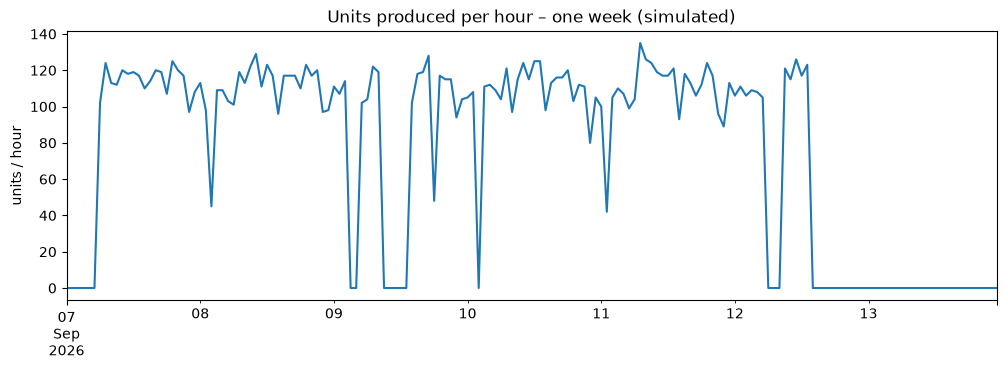

In [3]:
week = df[(df.timestamp >= "2026-09-07") & (df.timestamp < "2026-09-14")]
ax = week.plot(x="timestamp", y="units_produced", figsize=(12, 3.5), legend=False)
ax.set(title="Units produced per hour – one week (simulated)", xlabel="", ylabel="units / hour")
plt.show()

## Average output by hour and weekday
This is the pattern the features `hour` and `day_of_week` should capture.

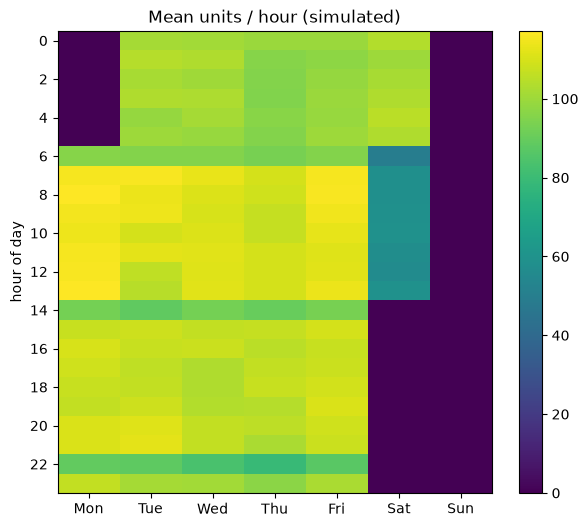

In [4]:
pivot = df.pivot_table(index=df.timestamp.dt.hour, columns=df.timestamp.dt.day_name().str[:3],
                       values="units_produced", aggfunc="mean")
pivot = pivot[["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]]
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(pivot, aspect="auto", cmap="viridis")
ax.set(xticks=range(7), xticklabels=pivot.columns, yticks=range(0, 24, 2), ylabel="hour of day",
       title="Mean units / hour (simulated)")
fig.colorbar(im, ax=ax)
plt.show()

## Line status
Planned stops (`off`, `maintenance`) are known in advance; `breakdown` is not – it is the main source of forecast error.

In [5]:
df.status.value_counts().to_frame("hours")

,hours
status,
running,11970
off,4496
breakdown,444
maintenance,416
changeover,194


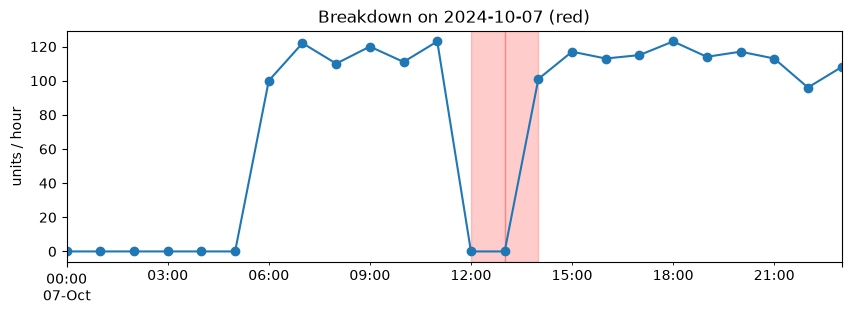

In [6]:
# Example: a day with a breakdown
day = df.loc[df.status.eq("breakdown").idxmax(), "timestamp"].normalize()
one_day = df[df.timestamp.dt.normalize() == day]
ax = one_day.plot(x="timestamp", y="units_produced", figsize=(10, 3), legend=False, marker="o")
for _, row in one_day[one_day.status == "breakdown"].iterrows():
    ax.axvspan(row.timestamp, row.timestamp + pd.Timedelta(hours=1), color="red", alpha=0.2)
ax.set(title=f"Breakdown on {day.date()} (red)", xlabel="", ylabel="units / hour")
plt.show()

## Naive baseline: "same hour yesterday"
The forecast model in Stage 4 must beat this. Evaluated on the last 8 weeks (later the test period).
`lag 168h` (same hour last week) is shown for comparison.

In [7]:
s = df.set_index("timestamp").units_produced
test = s.index >= s.index.max() - pd.Timedelta(weeks=8)
mae_24 = (s - s.shift(24))[test].abs().mean()
mae_168 = (s - s.shift(168))[test].abs().mean()
print(f"MAE same hour yesterday : {mae_24:.1f} units/hour")
print(f"MAE same hour last week : {mae_168:.1f} units/hour")

MAE same hour yesterday : 40.6 units/hour
MAE same hour last week : 16.3 units/hour


## Takeaways
- Strong daily (shift) and weekly (Sat/Sun) pattern → features `hour`, `day_of_week`, `lag_168h`.
- "Same hour yesterday" is weak at week boundaries (Monday after an empty Sunday) → MAE ~41 units/hour.
  "Same hour last week" is much better (~16). The Stage 4 model must beat the official baseline and should aim below lag 168h.
- Breakdowns are random and cannot be forecast; they also leak into tomorrow's `lag_24h` as a false dip.